
# Flipkart E-Commerce Capstone Project

## Project Title
Flipkart E-commerce Decision Intelligence Using Machine Learning

### Domain
E-commerce

### Project Objectives
1. Analyze e-commerce customer purchasing behaviour.
2. Estimate Average Order Value (AOV).
3. Predict customer churn.
4. Perform customer segmentation using K-Means clustering.
5. Apply PCA for dimensionality reduction.
6. Compare machine learning models.

### Technologies Used
- Python
- NumPy
- Pandas
- Matplotlib
- Seaborn
- Jupyter Notebook
- Machine Learning

### Project Type
Artificial Intelligence and Machine Learning Capstone


In [5]:

# Step 1: Import Required Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import os
import warnings

warnings.filterwarnings('ignore')

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

print("All Libraries Imported Successfully!")
print("Flipkart E-commerce Capstone Project Started")


All Libraries Imported Successfully!
Flipkart E-commerce Capstone Project Started


In [6]:

# Step 2: Create Project Folders

folders = [
    "data",
    "outputs",
    "models"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Project folders created successfully!")

print(os.listdir())


Project folders created successfully!
['.cache', '.codex', '.copilot', '.ipynb_checkpoints', '.ipython', '.jupyter', '.ms-ad', '.streamlit', '.vscode', '.vscode-shared', '21.ipynb', 'AppData', 'Application Data', 'archive.zip', 'Assignment1.ipynb', 'Assignment1_Q1_1_FCNN.ipynb', 'CNN_Geometry_Convolutions_Solution.ipynb', 'configuration-Office365-x64.xml', 'Contacts', 'Cookies', 'CrossDevice', 'Customer_Churn_Prediction.ipynb', 'customer_churn_project', 'data', 'Diwali_sales_data (1).csv', 'Documents', 'Downloads', 'Favorites', 'Flipkart E-Commerce Capstone.ipynb', 'index.html', 'IntelGraphicsProfiles', 'jupyter.ipynb', 'Links', 'Local Settings', 'Microsoft', 'models', 'Music', 'My Documents', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{3e51546f-8d63-11f0-b0ab-3cf011b5944c}.TM.blf', 'NTUSER.DAT{3e51546f-8d63-11f0-b0ab-3cf011b5944c}.TM.blf.cnpf', 'NTUSER.DAT{3e51546f-8d63-11f0-b0ab-3cf011b5944c}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{3e5

In [7]:

# Step 3: Generate Flipkart E-commerce Dataset

np.random.seed(42)

n = 800

data = {
    "Customer_ID": range(1001, 1001+n),
    "Age": np.random.randint(18, 65, n),
    "Gender": np.random.choice(["Male", "Female"], n),
    "City_Tier": np.random.choice(["Tier 1", "Tier 2", "Tier 3"], n),
    "Membership": np.random.choice(["Regular", "Premium", "VIP"], n),
    "Tenure_Months": np.random.randint(1, 61, n),
    "Monthly_Visits": np.random.randint(1, 25, n),
    "Orders_Last_6_Months": np.random.randint(1, 20, n),
    "Discounts_Used": np.random.randint(0, 15, n),
    "Returns": np.random.randint(0, 6, n),
    "Support_Tickets": np.random.randint(0, 8, n),
    "Late_Deliveries": np.random.randint(0, 6, n),
    "Payment_Method": np.random.choice(
        ["UPI", "Credit Card", "Debit Card", "COD"], n
    )
}

df = pd.DataFrame(data)

# Generate Average Order Value (AOV)
df["Average_Order_Value"] = (
    500
    + df["Age"] * 8
    + df["Monthly_Visits"] * 35
    + df["Orders_Last_6_Months"] * 20
    + df["Discounts_Used"] * 5
    + np.where(df["Membership"] == "Premium", 300, 0)
    + np.where(df["Membership"] == "VIP", 600, 0)
    + np.random.normal(0, 250, n)
).clip(200, 10000).round(2)

# Generate Total Spending
df["Total_Spending"] = (
    df["Average_Order_Value"] * df["Orders_Last_6_Months"]
).round(2)

# Generate Customer Churn
churn_score = (
    (df["Tenure_Months"] < 12).astype(int)
    + (df["Support_Tickets"] >= 5).astype(int)
    + (df["Late_Deliveries"] >= 3).astype(int)
    + (df["Monthly_Visits"] < 5).astype(int)
)

df["Churn"] = np.where(churn_score >= 2, 1, 0)

# Display dataset
print("Dataset Created Successfully!")
print("Total Customers:", len(df))
print("Total Columns:", len(df.columns))

df.head()


Dataset Created Successfully!
Total Customers: 800
Total Columns: 16


,Customer_ID,Age,Gender,City_Tier,Membership,Tenure_Months,Monthly_Visits,Orders_Last_6_Months,Discounts_Used,Returns,Support_Tickets,Late_Deliveries,Payment_Method,Average_Order_Value,Total_Spending,Churn
0,1001,56,Male,Tier 2,Premium,55,2,19,6,5,4,5,Debit Card,1765.79,33550.01,1
1,1002,46,Female,Tier 1,Premium,33,11,5,4,3,6,0,COD,2003.33,10016.65,0
2,1003,32,Female,Tier 1,Regular,17,22,8,2,0,6,2,Credit Card,1606.39,12851.12,0
3,1004,60,Male,Tier 2,VIP,24,13,7,3,4,0,1,COD,2302.40,16116.80,0
4,1005,25,Female,Tier 3,Regular,34,15,14,3,5,3,5,UPI,1331.93,18647.02,0


In [8]:

# Save Dataset

df.to_csv("data/flipkart_customers.csv", index=False)

print("Dataset saved successfully!")
print("File: data/flipkart_customers.csv")


Dataset saved successfully!
File: data/flipkart_customers.csv


In [9]:

# Dataset Information

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()


Dataset Shape: (800, 16)

Column Names:
['Customer_ID', 'Age', 'Gender', 'City_Tier', 'Membership', 'Tenure_Months', 'Monthly_Visits', 'Orders_Last_6_Months', 'Discounts_Used', 'Returns', 'Support_Tickets', 'Late_Deliveries', 'Payment_Method', 'Average_Order_Value', 'Total_Spending', 'Churn']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Customer_ID           800 non-null    int64  
 1   Age                   800 non-null    int32  
 2   Gender                800 non-null    str    
 3   City_Tier             800 non-null    str    
 4   Membership            800 non-null    str    
 5   Tenure_Months         800 non-null    int32  
 6   Monthly_Visits        800 non-null    int32  
 7   Orders_Last_6_Months  800 non-null    int32  
 8   Discounts_Used        800 non-null    int32  
 9   Returns               80

In [10]:

# Step 4: Data Cleaning

print("Dataset Shape:", df.shape)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Remove duplicates
df.drop_duplicates(inplace=True)

# Check data types
print("\nData Types:")
print(df.dtypes)

print("\nData Cleaning Completed Successfully!")


Dataset Shape: (800, 16)

Missing Values:
Customer_ID             0
Age                     0
Gender                  0
City_Tier               0
Membership              0
Tenure_Months           0
Monthly_Visits          0
Orders_Last_6_Months    0
Discounts_Used          0
Returns                 0
Support_Tickets         0
Late_Deliveries         0
Payment_Method          0
Average_Order_Value     0
Total_Spending          0
Churn                   0
dtype: int64

Duplicate Records: 0

Data Types:
Customer_ID               int64
Age                       int32
Gender                      str
City_Tier                   str
Membership                  str
Tenure_Months             int32
Monthly_Visits            int32
Orders_Last_6_Months      int32
Discounts_Used            int32
Returns                   int32
Support_Tickets           int32
Late_Deliveries           int32
Payment_Method              str
Average_Order_Value     float64
Total_Spending          float64
Churn         

In [11]:

# Step 5: Statistical Analysis

print("Statistical Summary:")
display(df.describe())

print("\nCustomer Churn Distribution:")
print(df["Churn"].value_counts())

print("\nMembership Distribution:")
print(df["Membership"].value_counts())


Statistical Summary:


,Customer_ID,Age,Tenure_Months,Monthly_Visits,Orders_Last_6_Months,Discounts_Used,Returns,Support_Tickets,Late_Deliveries,Average_Order_Value,Total_Spending,Churn
count,800.0000,800.00000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000
mean,1400.5000,41.19000,31.123750,12.690000,10.395000,7.215000,2.542500,3.450000,2.506250,1810.300450,19355.499900,0.355000
std,231.0844,13.32792,17.254944,6.950128,5.457904,4.313587,1.690197,2.330083,1.677342,440.427273,11925.582992,0.478813
min,1001.0000,18.00000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,484.240000,779.840000,0.000000
25%,1200.7500,30.00000,17.000000,7.000000,6.000000,3.000000,1.000000,1.000000,1.000000,1516.877500,9153.435000,0.000000
50%,1400.5000,42.00000,32.000000,13.000000,10.500000,7.000000,3.000000,4.000000,3.000000,1801.715000,18317.755000,0.000000
75%,1600.2500,52.00000,46.000000,19.000000,15.000000,11.000000,4.000000,5.000000,4.000000,2113.525000,27446.310000,1.000000
max,1800.0000,64.00000,60.000000,24.000000,19.000000,14.000000,5.000000,7.000000,5.000000,3196.380000,53539.150000,1.000000



Customer Churn Distribution:
Churn
0    516
1    284
Name: count, dtype: int64

Membership Distribution:
Membership
Premium    280
Regular    274
VIP        246
Name: count, dtype: int64


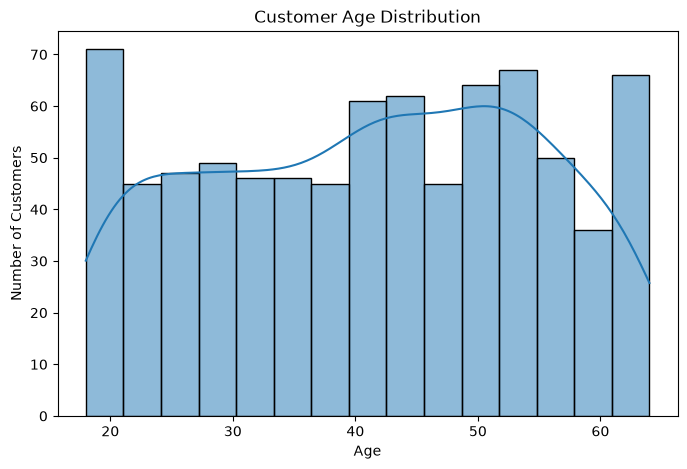

In [12]:

plt.figure(figsize=(8,5))

sns.histplot(df["Age"], bins=15, kde=True)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.show()


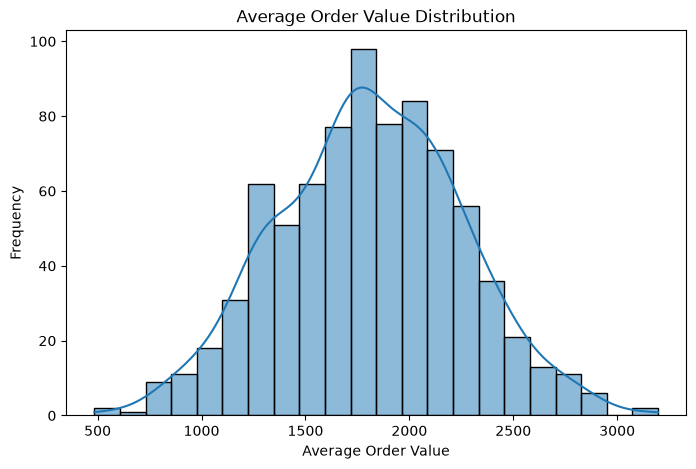

In [13]:

plt.figure(figsize=(8,5))

sns.histplot(df["Average_Order_Value"], kde=True)

plt.title("Average Order Value Distribution")
plt.xlabel("Average Order Value")
plt.ylabel("Frequency")

plt.show()


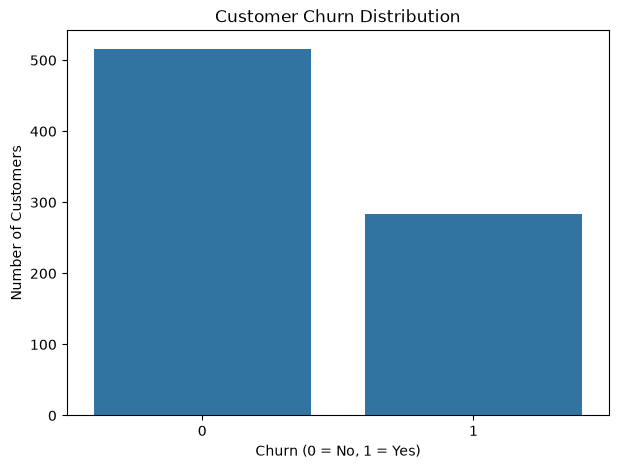

In [14]:

plt.figure(figsize=(7,5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")

plt.show()


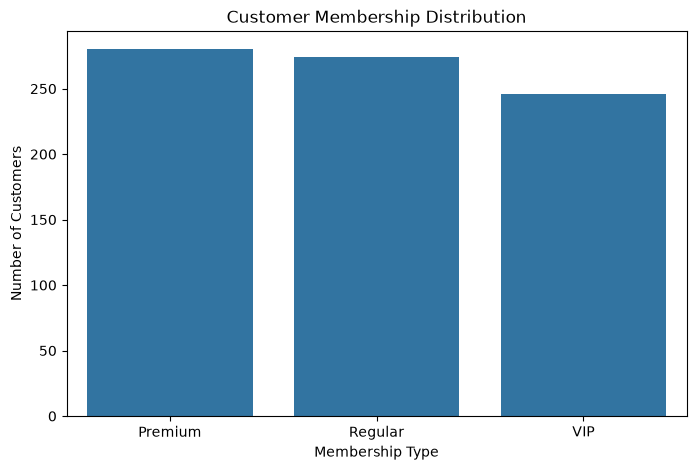

In [15]:

plt.figure(figsize=(8,5))

sns.countplot(data=df, x="Membership")

plt.title("Customer Membership Distribution")
plt.xlabel("Membership Type")
plt.ylabel("Number of Customers")

plt.show()


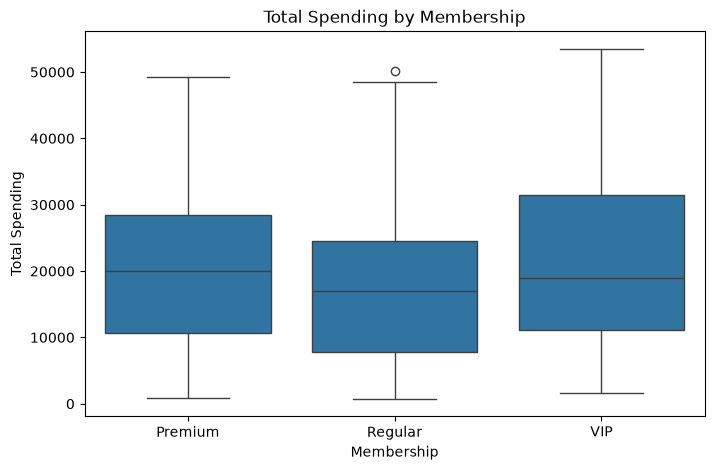

In [16]:

plt.figure(figsize=(8,5))

sns.boxplot(data=df, x="Membership", y="Total_Spending")

plt.title("Total Spending by Membership")
plt.xlabel("Membership")
plt.ylabel("Total Spending")

plt.show()


In [17]:

# Part 1: AOV Estimation - Data Preparation

# Select input features
X = df[
    ["Age", "Gender", "City_Tier", "Membership",
     "Tenure_Months", "Monthly_Visits",
     "Orders_Last_6_Months", "Discounts_Used"]
]

# Target variable
y = df["Average_Order_Value"]

# Convert categorical columns into numerical values
X = pd.get_dummies(X, drop_first=True, dtype=float)

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

display(X.head())


Input Features Shape: (800, 10)
Target Shape: (800,)


,Age,Tenure_Months,Monthly_Visits,Orders_Last_6_Months,Discounts_Used,Gender_Male,City_Tier_Tier 2,City_Tier_Tier 3,Membership_Regular,Membership_VIP
0,56,55,2,19,6,1.0,1.0,0.0,0.0,0.0
1,46,33,11,5,4,0.0,0.0,0.0,0.0,0.0
2,32,17,22,8,2,0.0,0.0,0.0,1.0,0.0
3,60,24,13,7,3,1.0,1.0,0.0,0.0,1.0
4,25,34,15,14,3,0.0,0.0,1.0,1.0,0.0


In [18]:

# Split dataset manually

np.random.seed(42)

indices = np.random.permutation(len(X))

train_size = int(0.8 * len(X))

train_indices = indices[:train_size]
test_indices = indices[train_size:]

X_train = X.iloc[train_indices].values
X_test = X.iloc[test_indices].values

y_train = y.iloc[train_indices].values
y_test = y.iloc[test_indices].values

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))


Training Records: 640
Testing Records: 160


In [19]:

# Standardize features using training data only

X_mean = X_train.mean(axis=0)
X_std = X_train.std(axis=0)
X_std[X_std == 0] = 1

X_train_scaled = (X_train - X_mean) / X_std
X_test_scaled = (X_test - X_mean) / X_std

# Standardize target
y_mean = y_train.mean()
y_std = y_train.std()

y_train_scaled = (y_train - y_mean) / y_std

# Add intercept column
X_train_b = np.c_[np.ones(len(X_train_scaled)), X_train_scaled]
X_test_b = np.c_[np.ones(len(X_test_scaled)), X_test_scaled]

# Initialize parameters
weights = np.zeros(X_train_b.shape[1])

learning_rate = 0.01
epochs = 3000
m = len(y_train_scaled)

# Gradient Descent
for epoch in range(epochs):

    predictions = X_train_b @ weights

    errors = predictions - y_train_scaled

    gradients = (2/m) * (X_train_b.T @ errors)

    weights -= learning_rate * gradients

print("Linear Regression Model Trained Successfully!")


Linear Regression Model Trained Successfully!


In [20]:

# Make predictions

y_pred_scaled = X_test_b @ weights

y_pred = y_pred_scaled * y_std + y_mean

# Evaluation Metrics
mae = np.mean(np.abs(y_test - y_pred))

mse = np.mean((y_test - y_pred) ** 2)

rmse = np.sqrt(mse)

ss_total = np.sum((y_test - y_test.mean()) ** 2)
ss_residual = np.sum((y_test - y_pred) ** 2)

r2 = 1 - (ss_residual / ss_total)

print("AOV REGRESSION RESULTS")
print("----------------------")
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))


AOV REGRESSION RESULTS
----------------------
MAE: 216.43
MSE: 70292.02
RMSE: 265.13
R2 Score: 0.6304


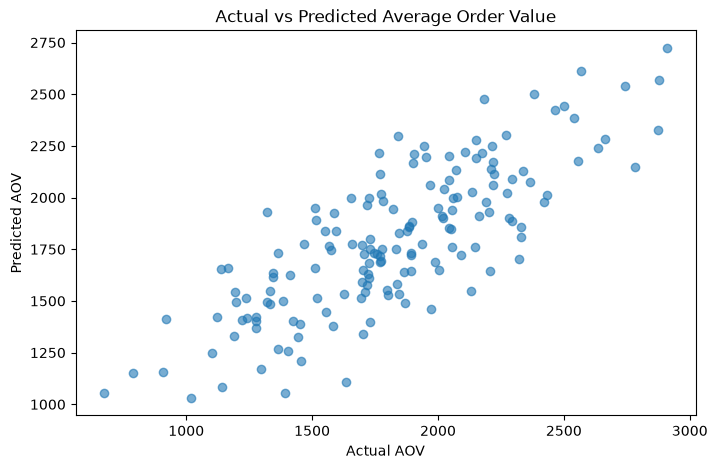

In [21]:

plt.figure(figsize=(8,5))

plt.scatter(y_test, y_pred, alpha=0.6)

plt.xlabel("Actual AOV")
plt.ylabel("Predicted AOV")

plt.title("Actual vs Predicted Average Order Value")

plt.show()


In [22]:

# PART 2: CUSTOMER CHURN PREDICTION

# Select features
churn_features = [
    "Age",
    "Tenure_Months",
    "Monthly_Visits",
    "Orders_Last_6_Months",
    "Support_Tickets",
    "Late_Deliveries",
    "Returns",
    "Discounts_Used"
]

X_churn = df[churn_features].values.astype(float)
y_churn = df["Churn"].values.astype(int)

# Train-test split
np.random.seed(42)

indices = np.random.permutation(len(X_churn))
train_size = int(0.8 * len(X_churn))

train_idx = indices[:train_size]
test_idx = indices[train_size:]

X_train_c = X_churn[train_idx]
X_test_c = X_churn[test_idx]

y_train_c = y_churn[train_idx]
y_test_c = y_churn[test_idx]

# Standardization
mean_c = X_train_c.mean(axis=0)
std_c = X_train_c.std(axis=0)
std_c[std_c == 0] = 1

X_train_c = (X_train_c - mean_c) / std_c
X_test_c = (X_test_c - mean_c) / std_c

print("Churn Dataset Prepared Successfully!")
print("Training Records:", len(X_train_c))
print("Testing Records:", len(X_test_c))
print("Churn Distribution:", np.bincount(y_churn))


Churn Dataset Prepared Successfully!
Training Records: 640
Testing Records: 160
Churn Distribution: [516 284]


In [23]:

# Logistic Regression using NumPy

def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

# Add intercept
X_train_log = np.c_[np.ones(len(X_train_c)), X_train_c]
X_test_log = np.c_[np.ones(len(X_test_c)), X_test_c]

weights_log = np.zeros(X_train_log.shape[1])

learning_rate = 0.1
epochs = 3000
m = len(y_train_c)

# Gradient Descent
for epoch in range(epochs):

    predictions = sigmoid(X_train_log @ weights_log)

    gradient = (X_train_log.T @
                (predictions - y_train_c)) / m

    weights_log -= learning_rate * gradient

# Predictions
log_probabilities = sigmoid(X_test_log @ weights_log)

y_pred_log = (log_probabilities >= 0.5).astype(int)

print("Logistic Regression Trained Successfully!")


Logistic Regression Trained Successfully!


In [24]:

# Evaluation Function

def evaluate_model(y_true, y_pred, model_name):

    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))

    accuracy = (tp + tn) / len(y_true)
    precision = tp / (tp + fp) if (tp + fp) else 0
    recall = tp / (tp + fn) if (tp + fn) else 0

    f1 = (2 * precision * recall /
          (precision + recall)) if (precision + recall) else 0

    print("\n", model_name)
    print("--------------------------")
    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1 Score:", round(f1, 4))

    print("\nConfusion Matrix:")
    print(np.array([[tn, fp], [fn, tp]]))

    return accuracy, precision, recall, f1

log_results = evaluate_model(
    y_test_c, y_pred_log, "Logistic Regression"
)



 Logistic Regression
--------------------------
Accuracy: 0.8688
Precision: 0.8182
Recall: 0.8036
F1 Score: 0.8108

Confusion Matrix:
[[94 10]
 [11 45]]


In [25]:

# K-Nearest Neighbors using NumPy

def knn_predict(X_train, y_train, X_test, k=5):

    predictions = []

    for test_point in X_test:

        distances = np.sqrt(
            np.sum((X_train - test_point) ** 2, axis=1)
        )

        nearest_indices = np.argsort(distances)[:k]

        nearest_labels = y_train[nearest_indices]

        prediction = np.bincount(
            nearest_labels, minlength=2
        ).argmax()

        predictions.append(prediction)

    return np.array(predictions)


y_pred_knn = knn_predict(
    X_train_c, y_train_c, X_test_c, k=5
)

print("KNN Model Trained Successfully!")

knn_results = evaluate_model(
    y_test_c, y_pred_knn, "KNN (K=5)"
)


KNN Model Trained Successfully!

 KNN (K=5)
--------------------------
Accuracy: 0.825
Precision: 0.7917
Recall: 0.6786
F1 Score: 0.7308

Confusion Matrix:
[[94 10]
 [18 38]]


,Accuracy,Precision,Recall,F1 Score
Logistic Regression,0.86875,0.818182,0.803571,0.810811
KNN,0.82500,0.791667,0.678571,0.730769


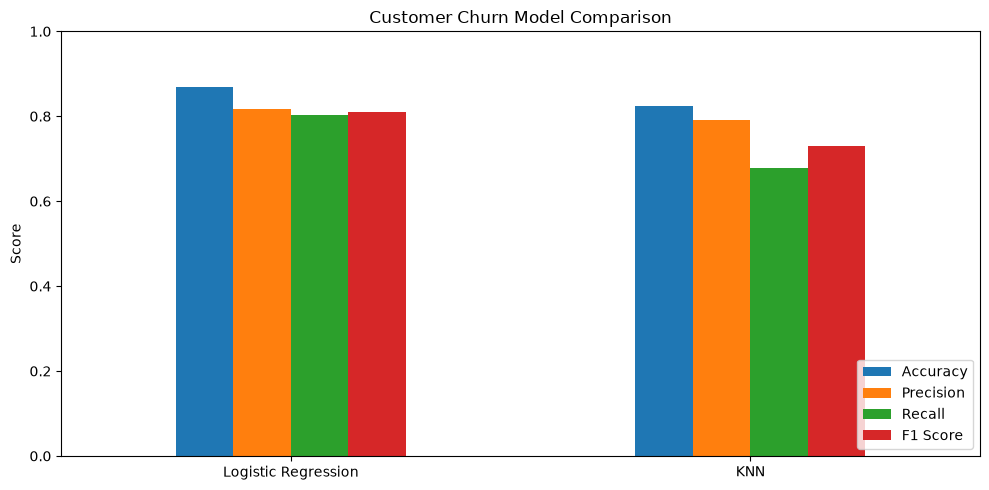

In [26]:

# Model Comparison

comparison = pd.DataFrame(
    [log_results, knn_results],
    columns=["Accuracy", "Precision", "Recall", "F1 Score"],
    index=["Logistic Regression", "KNN"]
)

display(comparison)

comparison.plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1),
    title="Customer Churn Model Comparison"
)

plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


In [27]:

# PART 3: CUSTOMER SEGMENTATION

cluster_features = [
    "Age",
    "Tenure_Months",
    "Monthly_Visits",
    "Orders_Last_6_Months",
    "Average_Order_Value",
    "Total_Spending",
    "Discounts_Used",
    "Returns"
]

X_cluster = df[cluster_features].values.astype(float)

# Standardization
cluster_mean = X_cluster.mean(axis=0)
cluster_std = X_cluster.std(axis=0)
cluster_std[cluster_std == 0] = 1

X_cluster_scaled = (X_cluster - cluster_mean) / cluster_std

print("Customer Segmentation Data Prepared!")
print("Records:", X_cluster_scaled.shape[0])
print("Features:", X_cluster_scaled.shape[1])


Customer Segmentation Data Prepared!
Records: 800
Features: 8


In [28]:

# K-Means Algorithm using NumPy

def kmeans(X, k=3, max_iters=100, seed=42):

    rng = np.random.default_rng(seed)

    indices = rng.choice(len(X), k, replace=False)

    centroids = X[indices].copy()

    for iteration in range(max_iters):

        distances = np.sqrt(
            ((X[:, np.newaxis, :] - centroids) ** 2).sum(axis=2)
        )

        labels = np.argmin(distances, axis=1)

        new_centroids = np.array([
            X[labels == i].mean(axis=0)
            if np.any(labels == i)
            else centroids[i]
            for i in range(k)
        ])

        if np.allclose(centroids, new_centroids):
            break

        centroids = new_centroids

    return labels, centroids


cluster_labels, centroids = kmeans(
    X_cluster_scaled, k=3
)

df["Customer_Segment"] = cluster_labels

print("K-Means Clustering Completed!")
print("\nCustomer Segment Distribution:")
print(df["Customer_Segment"].value_counts().sort_index())


K-Means Clustering Completed!

Customer Segment Distribution:
Customer_Segment
0    254
1    292
2    254
Name: count, dtype: int64


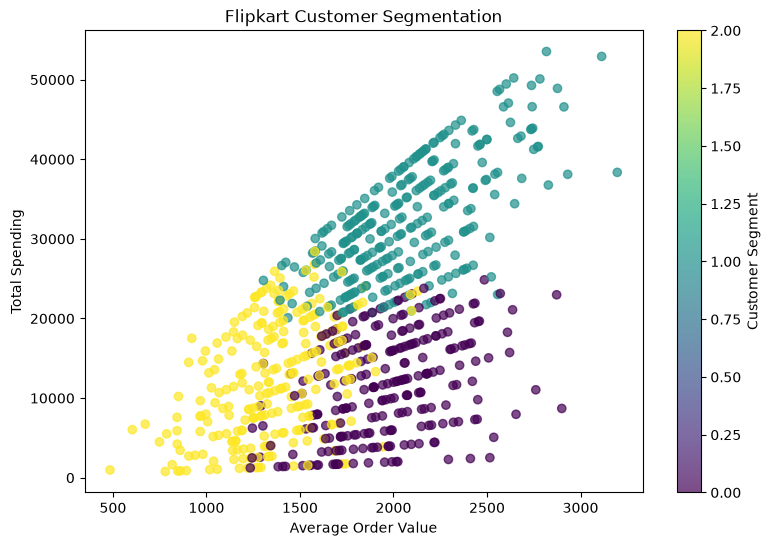

In [29]:

plt.figure(figsize=(9, 6))

plt.scatter(
    df["Average_Order_Value"],
    df["Total_Spending"],
    c=df["Customer_Segment"],
    cmap="viridis",
    alpha=0.7
)

plt.title("Flipkart Customer Segmentation")
plt.xlabel("Average Order Value")
plt.ylabel("Total Spending")
plt.colorbar(label="Customer Segment")

plt.show()


In [30]:

# Principal Component Analysis using NumPy

# Calculate covariance matrix
cov_matrix = np.cov(X_cluster_scaled, rowvar=False)

# Eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

# Sort in descending order
sorted_indices = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[sorted_indices]
eigenvectors = eigenvectors[:, sorted_indices]

# Select first two principal components
components = eigenvectors[:, :2]

# Transform dataset
X_pca = X_cluster_scaled @ components

print("PCA Completed Successfully!")
print("Original Features:", X_cluster_scaled.shape[1])
print("Reduced Features:", X_pca.shape[1])

explained_variance = (
    eigenvalues[:2].sum() / eigenvalues.sum()
)

print("Explained Variance Ratio:",
      round(explained_variance, 4))


PCA Completed Successfully!
Original Features: 8
Reduced Features: 2
Explained Variance Ratio: 0.4624


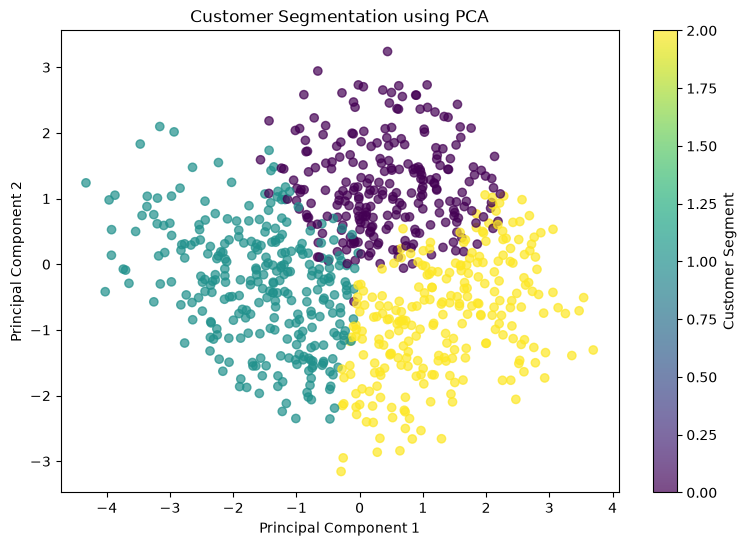

In [31]:

plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=cluster_labels,
    cmap="viridis",
    alpha=0.7
)

plt.title("Customer Segmentation using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Customer Segment")

plt.show()


In [32]:

# Analyze customer groups

segment_summary = df.groupby("Customer_Segment").agg({
    "Age": "mean",
    "Monthly_Visits": "mean",
    "Average_Order_Value": "mean",
    "Total_Spending": "mean",
    "Orders_Last_6_Months": "mean"
}).round(2)

display(segment_summary)


,Age,Monthly_Visits,Average_Order_Value,Total_Spending,Orders_Last_6_Months
Customer_Segment,,,,,
0,43.46,17.31,1958.97,11655.02,5.90
1,43.35,14.47,2070.43,32154.84,15.57
2,36.44,6.03,1362.58,12341.78,8.94


In [33]:

# PART 4: ADABOOST FROM SCRATCH

def train_adaboost(X, y, n_estimators=20):

    y_new = np.where(y == 1, 1, -1)

    n_samples, n_features = X.shape
    sample_weights = np.ones(n_samples) / n_samples

    stumps = []

    for iteration in range(n_estimators):

        best_error = float("inf")
        best_stump = None

        for feature in range(n_features):

            thresholds = np.unique(
                np.quantile(X[:, feature],
                            np.linspace(0.05, 0.95, 20))
            )

            for threshold in thresholds:

                for polarity in [-1, 1]:

                    predictions = np.ones(n_samples)

                    predictions[
                        X[:, feature] < threshold
                    ] = -1

                    predictions *= polarity

                    error = np.sum(
                        sample_weights[predictions != y_new]
                    )

                    if error < best_error:
                        best_error = error
                        best_stump = (
                            feature, threshold, polarity
                        )

        if best_stump is None or best_error >= 0.5:
            break

        best_error = np.clip(best_error, 1e-10, 1-1e-10)

        alpha = 0.5 * np.log(
            (1 - best_error) / best_error
        )

        feature, threshold, polarity = best_stump

        predictions = np.ones(n_samples)
        predictions[X[:, feature] < threshold] = -1
        predictions *= polarity

        sample_weights *= np.exp(
            -alpha * y_new * predictions
        )

        sample_weights /= sample_weights.sum()

        stumps.append((best_stump, alpha))

        if best_error <= 1e-10:
            break

    return stumps


def predict_adaboost(X, stumps):

    final_predictions = np.zeros(len(X))

    for stump, alpha in stumps:

        feature, threshold, polarity = stump

        predictions = np.ones(len(X))
        predictions[X[:, feature] < threshold] = -1
        predictions *= polarity

        final_predictions += alpha * predictions

    return (final_predictions >= 0).astype(int)


# Train AdaBoost
ada_model = train_adaboost(
    X_train_c, y_train_c, n_estimators=20
)

y_pred_ada = predict_adaboost(
    X_test_c, ada_model
)

print("AdaBoost Training Completed!")
print("Number of Weak Learners:", len(ada_model))

ada_results = evaluate_model(
    y_test_c, y_pred_ada, "AdaBoost"
)


AdaBoost Training Completed!
Number of Weak Learners: 20

 AdaBoost
--------------------------
Accuracy: 0.975
Precision: 0.9643
Recall: 0.9643
F1 Score: 0.9643

Confusion Matrix:
[[102   2]
 [  2  54]]


In [34]:

# ARTIFICIAL NEURAL NETWORK USING NUMPY

np.random.seed(42)

input_size = X_train_c.shape[1]
hidden_size = 12
output_size = 1

# Initialize weights
W1 = np.random.randn(input_size, hidden_size) * 0.1
b1 = np.zeros((1, hidden_size))

W2 = np.random.randn(hidden_size, output_size) * 0.1
b2 = np.zeros((1, output_size))


def sigmoid_nn(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))


# Training
learning_rate = 0.05
epochs = 3000

Y_train_nn = y_train_c.reshape(-1, 1)

for epoch in range(epochs):

    # Forward propagation
    Z1 = X_train_c @ W1 + b1
    A1 = np.maximum(0, Z1)

    Z2 = A1 @ W2 + b2
    A2 = sigmoid_nn(Z2)

    # Backpropagation
    m = len(Y_train_nn)

    dZ2 = A2 - Y_train_nn
    dW2 = (A1.T @ dZ2) / m
    db2 = np.sum(dZ2, axis=0, keepdims=True) / m

    dA1 = dZ2 @ W2.T
    dZ1 = dA1 * (Z1 > 0)

    dW1 = (X_train_c.T @ dZ1) / m
    db1 = np.sum(dZ1, axis=0, keepdims=True) / m

    # Update weights
    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2

    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

print("Neural Network Training Completed!")


Neural Network Training Completed!


In [35]:

# Neural Network Predictions

Z1_test = X_test_c @ W1 + b1
A1_test = np.maximum(0, Z1_test)

Z2_test = A1_test @ W2 + b2
A2_test = sigmoid_nn(Z2_test)

y_pred_nn = (A2_test.flatten() >= 0.5).astype(int)

nn_results = evaluate_model(
    y_test_c, y_pred_nn, "Artificial Neural Network"
)



 Artificial Neural Network
--------------------------
Accuracy: 0.9062
Precision: 0.8596
Recall: 0.875
F1 Score: 0.8673

Confusion Matrix:
[[96  8]
 [ 7 49]]


FINAL MODEL PERFORMANCE COMPARISON


,Accuracy,Precision,Recall,F1 Score
Logistic Regression,0.8688,0.8182,0.8036,0.8108
KNN,0.8250,0.7917,0.6786,0.7308
AdaBoost,0.9750,0.9643,0.9643,0.9643
Neural Network,0.9062,0.8596,0.8750,0.8673


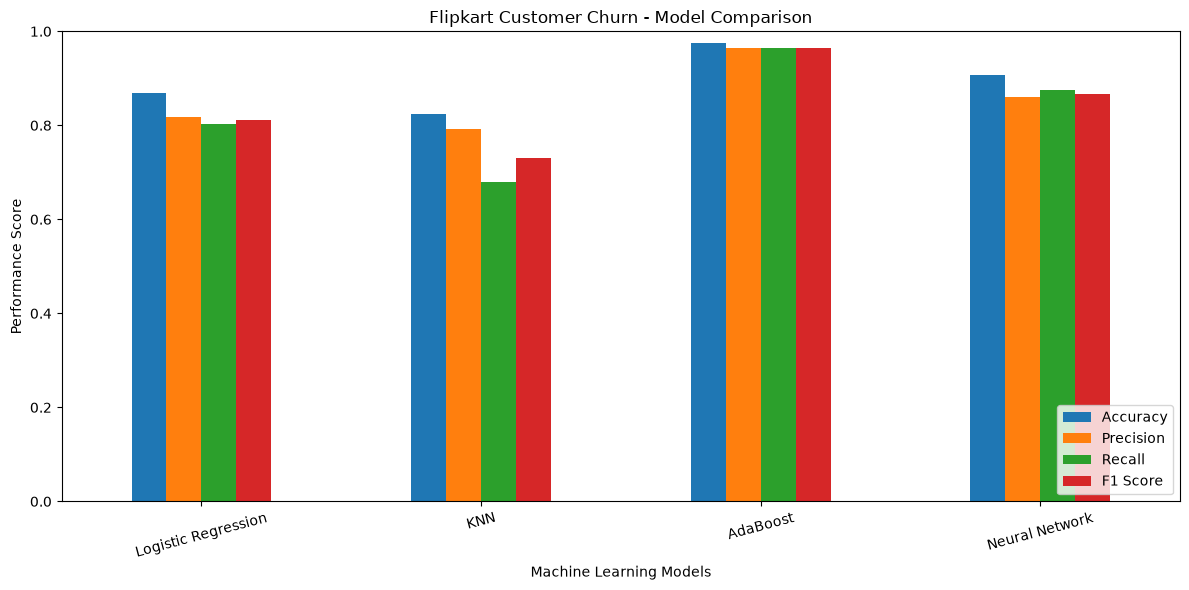

In [36]:

# Final Classification Model Comparison

final_comparison = pd.DataFrame(
    [
        log_results,
        knn_results,
        ada_results,
        nn_results
    ],
    columns=["Accuracy", "Precision", "Recall", "F1 Score"],
    index=[
        "Logistic Regression",
        "KNN",
        "AdaBoost",
        "Neural Network"
    ]
)

print("FINAL MODEL PERFORMANCE COMPARISON")

display(final_comparison.round(4))

# Plot comparison
final_comparison.plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
    title="Flipkart Customer Churn - Model Comparison"
)

plt.ylabel("Performance Score")
plt.xlabel("Machine Learning Models")
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


In [37]:

# Save final outputs

final_comparison.to_csv(
    "outputs/final_model_comparison.csv"
)

segment_summary.to_csv(
    "outputs/customer_segment_analysis.csv"
)

df.to_csv(
    "outputs/flipkart_final_dataset.csv",
    index=False
)

print("All Final Results Saved Successfully!")
print("Files saved in outputs folder.")


All Final Results Saved Successfully!
Files saved in outputs folder.


In [38]:

# Step 32: Create README and Requirements Files

readme_content = """
# Flipkart E-Commerce Capstone Project

## Project Overview
This project analyzes simulated e-commerce customer data
using Python and Machine Learning algorithms.

## Dataset
- 800 simulated customer records
- Customer demographics
- Shopping behaviour
- Average Order Value
- Customer Churn
- Customer Spending

## Project Modules

### Part 1: AOV Estimation
- Linear Regression from Scratch
- MAE, MSE, RMSE and R2 Score

### Part 2: Customer Churn Prediction
- Logistic Regression from Scratch
- K-Nearest Neighbors (KNN)
- Accuracy, Precision, Recall and F1 Score

### Part 3: Customer Segmentation
- K-Means Clustering from Scratch
- Principal Component Analysis (PCA)

### Part 4: Advanced Machine Learning
- AdaBoost from Scratch
- Artificial Neural Network using NumPy
- Model Comparison

## Technologies Used
- Python
- NumPy
- Pandas
- Matplotlib
- Seaborn
- Jupyter Notebook

## Project Structure
- data/
- outputs/
- models/
- Flipkart_Capstone.ipynb
- README.md
- requirements.txt

## Important Note
The dataset is synthetically generated for educational
and academic purposes. It is not actual Flipkart customer data.
"""

with open("README.md", "w", encoding="utf-8") as f:
    f.write(readme_content)

requirements = """
numpy
pandas
matplotlib
seaborn
jupyter
"""

with open("requirements.txt", "w", encoding="utf-8") as f:
    f.write(requirements.strip())

print("README.md created successfully!")
print("requirements.txt created successfully!")


README.md created successfully!
requirements.txt created successfully!
